In [1]:
using LinearAlgebra
using PyPlot
using Trapz
using Calculus

In [2]:
function H_dna(
        energies,#::Array{Float64},
        thopping#::Float64
        )
    N = length(energies)
    M_all = zeros(Float64, N,N)
    for i in 1:N
        M_all[i, i] = energies[i]
        if i<N
            M_all[i, i+1] = thopping            
            M_all[i+1, i] = thopping
        end 
    end
    return Matrix(M_all)
end 
function G_und_trans(energy::Float64,
        eta::Float64,
        Hamiltonian::Array{Float64},
        gammas::Array{Float64})
    dim = Integer(sqrt(length( Hamiltonian))) # size(H)
    Matrix_I_e = (energy + eta*1im ) * Matrix(I, dim,dim)
   # gamma_l = Matrix([gamma_l1 0; 0 gamma_l2]) # for two coupling parameters to both leads
    #gamma_r = Matrix([gamma_r1 0 ; 0 gamma_r2]) #-1im* (gamma_l+ gamma_r)/2
    
    #I don'tknow if this is correct??!
    
    
    gamma_l = zeros(Float64, dim,dim)
   # gamma_l = Matrix{Float64}(I,dim, dim)
    gamma_l[1, 1] = gammas[1]
    gamma_r = zeros(Float64, dim,dim)
    #gamma_r = Matrix{Float64}( I, dim, dim)
    gamma_r[end, end] = gammas[2]
   
    matrix_self = -1im *(gamma_l+ gamma_r)/ 2 
    G_ret =  inv(Matrix_I_e - matrix_self - Hamiltonian)
    G_adv = adjoint(G_ret)
    final_Matrix = gamma_l* G_adv * gamma_r * G_ret
    return real.(tr(final_Matrix))
end 

G_und_trans (generic function with 1 method)

[-0.11030516516448619, 0.20873282713931918, 0.47202901976518397, 0.727970980234816, 0.991267172860681, 1.3103051651644875]6

sys:1: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.
sys:1: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.


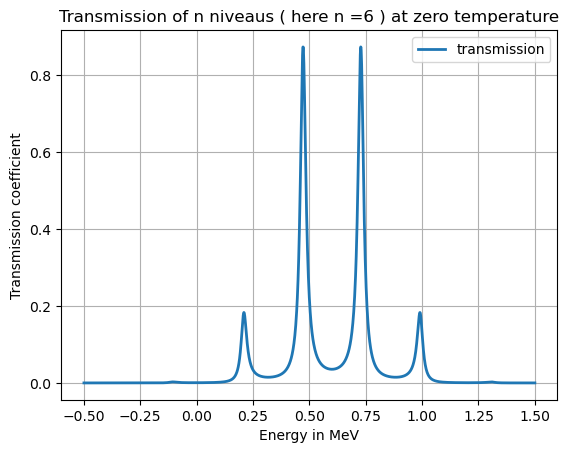

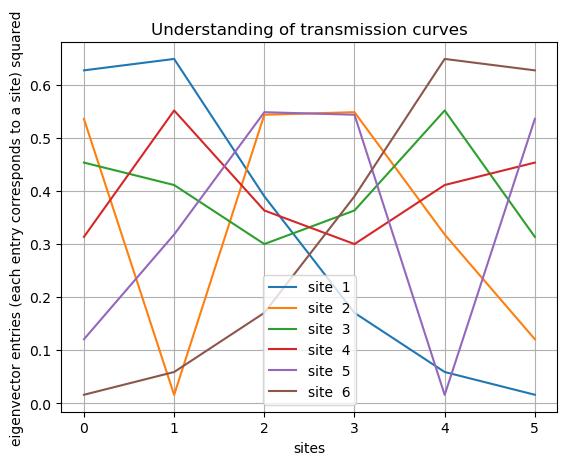

In [28]:
#looking at the Hamiltonian
energy_levels = range(0.2, 1, length =6) # collect(
H_bsp = H_dna(energy_levels,0.3 )
#show(H_bsp)

# defining variable for G        
emin, emax = -0.5, 1.5
E_list = range(emin, emax, length = 2000)
eta = 10^(-7)
gammas = Array([.1 .1])
transm_bsp = [G_und_trans(E,eta, H_bsp, gammas) for E in E_list]

plt.plot(
    E_list, transm_bsp,    #mit f. normalerweise komponentenweise
    label = "transmission",
    linewidth = 2 
    )
plt.legend()
#plt.ylim( 0, 0.05)
plt.title("Transmission of n niveaus ( here n =6 ) at zero temperature")
plt.xlabel( "Energy in MeV")
plt.ylabel( "Transmission coefficient")
plt.grid("true")
plt.savefig("transmission_n_niv.pdf")
plt.show()

ei, vec = eigen(H_bsp)
print(ei, size(vec)[1]) ##typeof(H))
plt.figure()
for i in range(1, size(vec)[1], step = 1)
    plt.plot(abs.(vec[:,i]), label="site  "*string(i))
end
plt.grid("both")
plt.legend()
plt.title( "Understanding of transmission curves")
plt.ylabel("eigenvector entries (each entry corresponds to a site) squared")
plt.xlabel("sites")
plt.savefig("eigen_vec^2_n_niv.pdf")
plt.show()

In [4]:
function integral_f(x_data::Array{Float64}, H::Array{Float64},  eta::Float64, gammas::Array{Float64})
    y_int = []
    for i in 1:(length(x_data)-1)
        x_neu  = range(x_data[i], x_data[i+1], length = 10)
        
        y_neu = [G_und_trans(x/ 2,eta, H, gammas) for x in x_neu]
        if i ==1
            push!(y_int, trapz(x_neu, y_neu))
        end
        if i > 1
            s = y_int[i-1] +  trapz(x_neu, y_neu)
            push!(y_int, s)
        end
    end
        plt.plot(x_data[1:end-1], y_int, label= "current")
       
    return y_int
end

function I_max( gammas::Array{Float64}, H::Array{Float64}) # Tr( Γ_L G^A Γ_R G^R)
    dim = Integer(sqrt(length( H)))
    #I don'tknow if this is correct??!
    
    
    gamma_l = zeros(Float64, dim,dim)
   # gamma_l = Matrix{Float64}(I,dim, dim)
    gamma_l[1, 1] = gammas[1]
        
    gamma_r = zeros(Float64, dim,dim)
    #gamma_r = Matrix{Float64}( I, dim, dim)
    gamma_r[dim, dim] = gammas[2]
     

    ei, vec = eigen(H)
    U_deg = vec'
    gamma_l_deg = U_deg*gamma_l * vec
    gamma_r_deg =  U_deg*gamma_r * vec
    I1 = gamma_l_deg[1,1]* gamma_r_deg[1, 1]/(gamma_l_deg[1,1] + gamma_r_deg[1, 1])  
    I2 = gamma_l_deg[end,end]* gamma_r_deg[end, end]/(gamma_l_deg[end,end] + gamma_r_deg[end, end])
    return I1 + I2
end

I_max (generic function with 1 method)

I max from modell is:  5.0454804469543324e-5

sys:1: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.


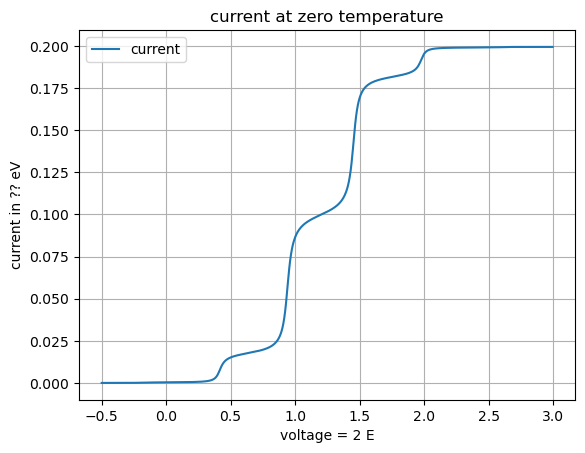

In [5]:
u_list= Array(range(-.5,3., length = 1000))
plt.figure( )
integral_f(u_list, H_bsp,  eta, gammas)
plt.grid( "true")
plt.legend()
plt.xlabel( "voltage = 2 E")
plt.ylabel( "current in ?? eV")
plt.title( "current at zero temperature")
plt.savefig("current_n_niv.pdf")
plt.show()

print( "I max from modell is:  ", I_max( gammas, H_bsp))

In [6]:
function fermi(
        e::Float64,mu_s::Float64, phi_s::Float64, temp_s::Float64)
    return 1/(exp((e- mu_s - phi_s)/temp_s)+ 1) 
end
function to_integrate(
        e, #::Array{Float64},
        transm::Array{Float64},
        mu_l::Float64, phi_l::Float64, temp_l::Float64, mu_r::Float64, phi_r::Float64, temp_r::Float64 )
    fermi_l = Array([fermi(energy,  mu_l, phi_l, temp_l) for energy in e])
    fermi_r = Array([fermi(energy,  mu_r, phi_r, temp_r) for energy in e] )
    return transm.*(fermi_l .- fermi_r)
end
function integral_f_fermi(
        x_data::Array{Float64}, H::Array{Float64},  eta::Float64, gammas::Array{Float64},
        mu_l::Float64, phi_l::Float64, temp_l::Float64, mu_r::Float64, phi_r::Float64, temp_r::Float64)
    y_int = []
    for i in 1:(length(x_data)-1)
        x_neu  = range(x_data[i], x_data[i+1], length = 10)
        
        trans_neu = [G_und_trans(x/ 2,eta, H, gammas) for x in x_neu]
        y_neu = to_integrate(x_neu./2 , trans_neu,  mu_l, phi_l, temp_l, mu_r, phi_r, temp_r )
        if i ==1
            push!(y_int, trapz(x_neu, y_neu))
        end
        if i > 1
            s = y_int[i-1] +  trapz(x_neu, y_neu)
            push!(y_int, s)
        end
    end
        plt.plot(x_data[1:end-1], y_int, label= "current")
       
    return y_int
end

integral_f_fermi (generic function with 1 method)

sys:1: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.


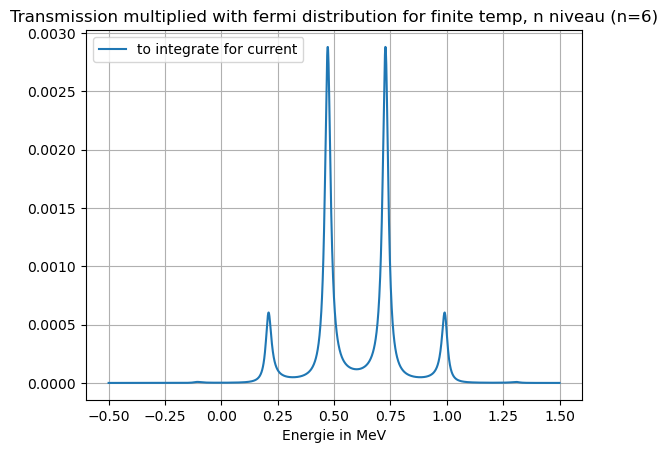

In [8]:
mu_l , phi_l, temp_l = .0, 0.75, 25.
mu_r, phi_r, temp_r = .0, .42, 25. # wenn die rechte Temp höher ist, wird die differenz der fermi funktionen negativ
# d.h. Kurve ist gespiegelt

transm_fermi = to_integrate( E_list, transm_bsp, mu_l , phi_l, temp_l,mu_r, phi_r, temp_r)
plt.plot( E_list,transm_fermi, 
    label = "to integrate for current"
    )
plt.legend()
plt.title("Transmission multiplied with fermi distribution for finite temp, n niveau (n=6)")
#plt.ylim( -0.01, 0.03)
plt.xlabel("Energie in MeV")
plt.grid("true")
plt.savefig("transm and fermi_n_niv.pdf")
plt.show()

